In [75]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.utils.data import Dataset
from PIL import Image
from torchsummary import summary
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold
from torch.utils.data import Subset

"""
Importing everything I will need

and defining the device that I want to use for training
"""

print(torch.version.cuda)  # Should not be None
print(torch.backends.cudnn.enabled)  # Should be True

# Get cpu or gpu device for training.
device = (
    "cuda" if torch.cuda.is_available()
     else "cpu"
)
print(f"Using {device} device")

11.8
True
Using cuda device


<H1> Part 1:
In your own words, answer the following questions: </h1>
<p style="font-size:15px;">
a: In your opinion, what were the most important turning points in the history of deep learning?

Answer: Milestones in the history of deep learning in chronological order:
   - The invention of the perceptron marked a foundational moment in the history of neural networks, as it introduced the concept of learning machines and laid the groundwork for subsequent advancements in the field.
   - The development of the backpropagation algorithm was a critical breakthrough, enabling the optimization of models that lack simple analytical solutions. This advancement made it feasible to train multi-layer neural networks (MLPs), demonstrating that such architectures could effectively tackle complex problems.
   - The emergence of Convolutional Neural Networks (CNNs), initially pioneered by Yann LeCun and later popularized by AlexNet, provided evidence of their practical applicability for visual recognition tasks. These models significantly advanced the field of computer vision.
   - The introduction of Transformers, particularly through the paper "Attention is All You Need", revolutionized the landscape of deep learning. This architecture enabled the development of Large Language Models (LLMs) in the form we recognize today, transforming natural language processing and many other domains.

b: Explain the ADAM optimizer.
</p>
<p style="font-size:15px;">
Answer: Adaptive moment estimation (ADAM) is the combination of Momentum and RMSProp, taking the best of both worlds ADAM is fast to converge and good at handling noisy data or sparse gradients. So practically ADAM does:
<ul>
   <li> Compute the gradient.</li>
   <li> Update the momentum estimate, that is the moving average of the gradients.</li>
   <li> Update biased second moment estimate (uncentered variance).</li>
   <li> Correct bias in moment estimates.</li>
   <li> And in the end update parameters.</li>
</ul>
c: Assume data input is a single 30x40 pixel image. First layer is a convolutional layer with 5 filters, with kernel size 3x2, step size (1,1) and padding='valid'. What are the output dimensions?
<br>
Answer: The output dimensions would be 5x28x39
</p>

In [76]:
class NeuralNetwork1C(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=1,out_channels=5, kernel_size=(3, 2),stride=1,padding='valid')

    def forward(self, x):
        x = self.conv1(x)
        return x

model1C = NeuralNetwork1C().to(device)
print(model1C)
summary(model1C, input_size=(1, 30, 40), device=device)

NeuralNetwork1C(
  (conv1): Conv2d(1, 5, kernel_size=(3, 2), stride=(1, 1), padding=valid)
)
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1            [-1, 5, 28, 39]              35
Total params: 35
Trainable params: 35
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.04
Params size (MB): 0.00
Estimated Total Size (MB): 0.05
----------------------------------------------------------------


d: Assuming ReLU activations and offsets, and that the last layer is softmax, how many parameters does this network have:

<img src="diagram.png" width="500"/>

Answer: For each of the first 3 layers we have ((5 * 5) + 5) parameters, and for the last layer 3 * 5 + 3, therefore in total we have 108 = ((5 * 5) + 5 ) * 3 + (3 * 5) + 3

In [77]:
class NeuralNetwork1D(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(5, 5,bias=True),
            nn.ReLU(inplace=True),
            nn.Linear(5, 5,bias=True),
            nn.ReLU(inplace=True),
            nn.Linear(5, 5,bias=True),
            nn.ReLU(inplace=True),
            nn.Linear(5, 3,bias=True)
        )

    def forward(self, x):
        x = self.linear_relu_stack(x)
        logits = nn.functional.softmax(x, dim=1)
        return logits

model1D = NeuralNetwork1D().to(device)
#print(model1D)
summary(model1D, input_size=(1, 5), device=device)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                 [-1, 1, 5]              30
              ReLU-2                 [-1, 1, 5]               0
            Linear-3                 [-1, 1, 5]              30
              ReLU-4                 [-1, 1, 5]               0
            Linear-5                 [-1, 1, 5]              30
              ReLU-6                 [-1, 1, 5]               0
            Linear-7                 [-1, 1, 3]              18
Total params: 108
Trainable params: 108
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


e: For a given minibatch, the targets are [1,4, 5, 8] and the network output is [0.1,4.4,0.2,10]. If the loss function is "torch.nn.HuberLoss(reduction='mean', delta=1.0)", what is the loss for this minibatch?

Answer: 1.57125 as we can see below

In [78]:
loss = torch.nn.HuberLoss(reduction='mean', delta=1.0)
targets = torch.tensor( np.array([1.0,4.0,5.0,8.0]))
predictions = torch.tensor( np.array([0.1,4.4,0.2,10.0]))

avg_loss = loss(predictions, targets).item()

print(avg_loss)

1.57125



<H1> Part 2: Writing a PyTorch dataset </H1>

The Insects.zip-file contains images of three species of bees. The Insects.csv -file has three columns of which you should focus on the one named "species" and the one named "filename". The "species" column tells the target label of the images listed in the "filename" column.

Your task is to write a PyTorch dataset, which provides image samples together with their target labels.

In [79]:
def class_map(s):
    match s:
        case "Andrena fulva":
            return 1
        case "Panurgus banksianus":
            return 2
        case "Lasioglossum punctatissimum":
            return 3
        case _:
            raise ValueError("Invalid input")
class CustomImageDataset(Dataset): # I create a custom dataset class
    def __init__(self, csv_file, transform=None):
        self.data = pd.read_csv(csv_file,delimiter=',') # the csv file is read
        self.transform = transform
    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_path = self.data.iloc[idx, 2]   # I get the image path from the pandas dataframe
        label = class_map(self.data.iloc[idx, 1])      # and the label
        image = Image.open(f"Insects/Insects/{img_path}").convert("RGB")

        if self.transform:
            image = self.transform(image) # I apply the transform to the image

        return image, int(label)


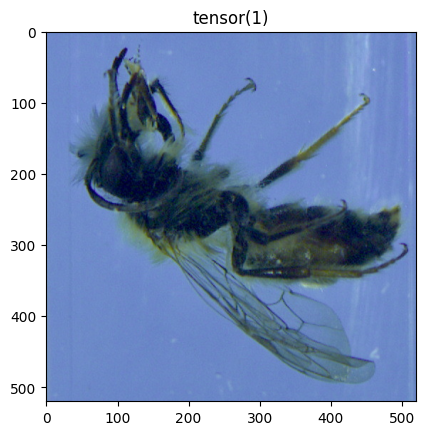

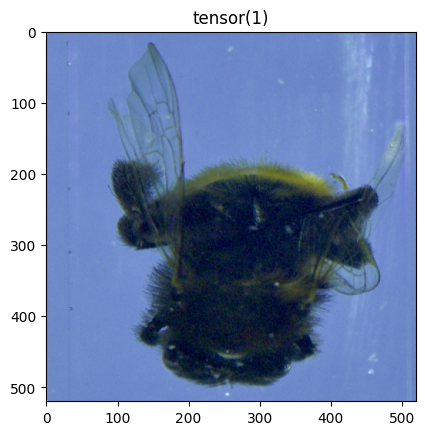

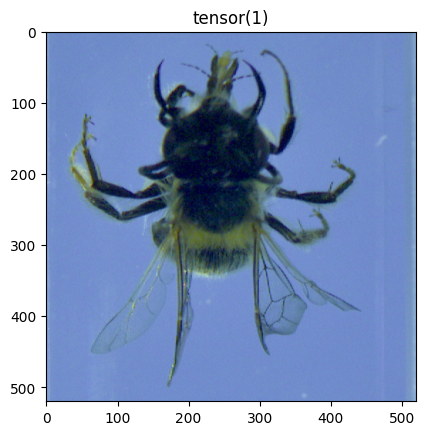

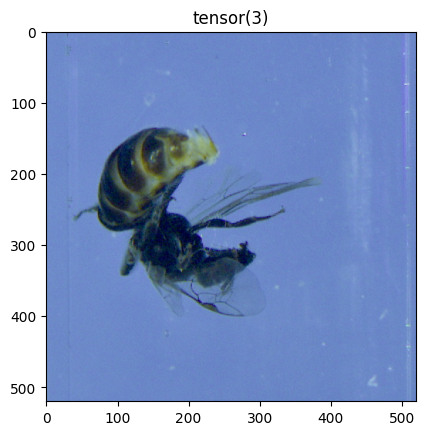

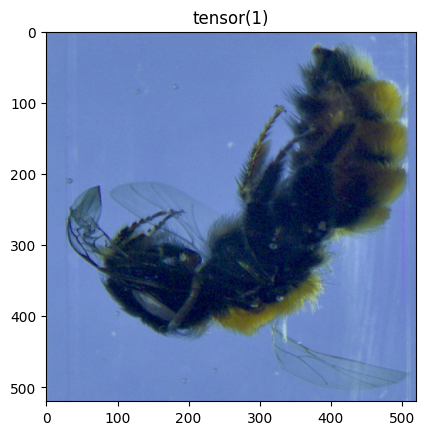

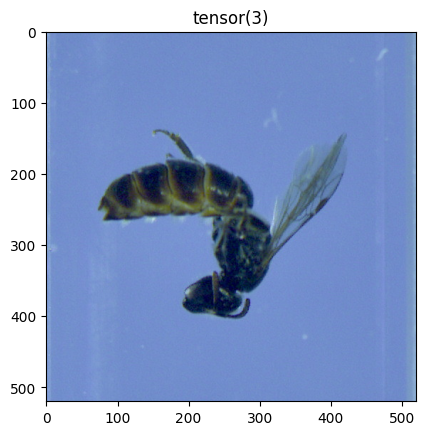

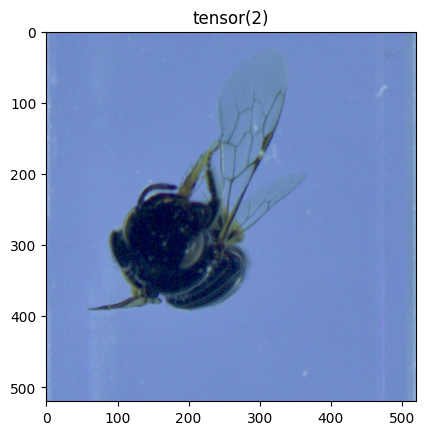

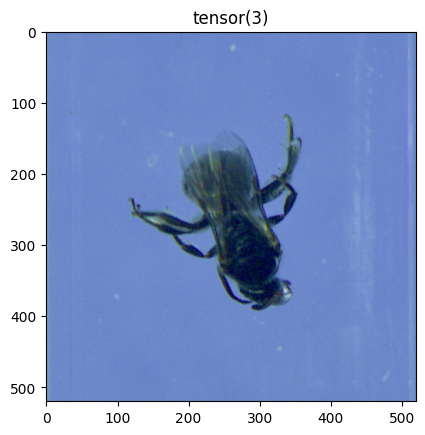

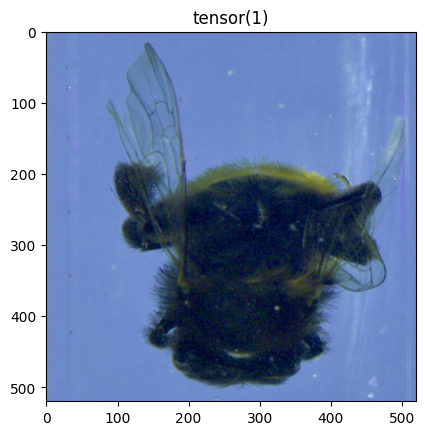

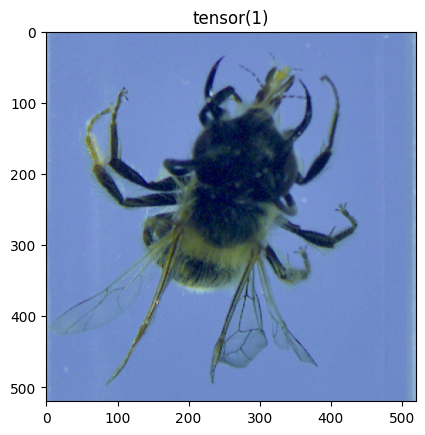

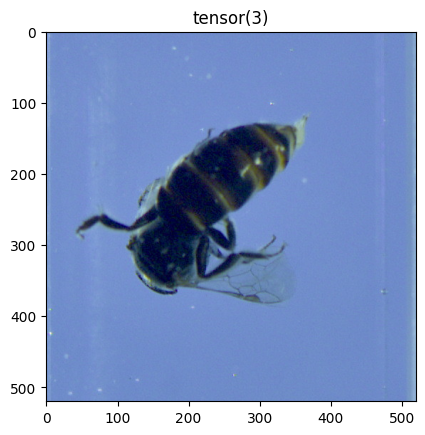

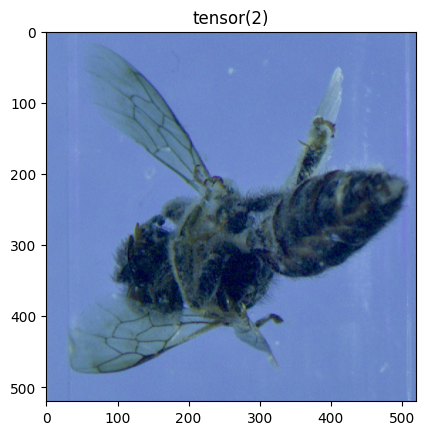

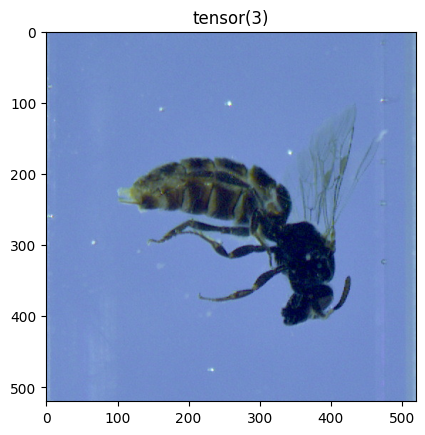

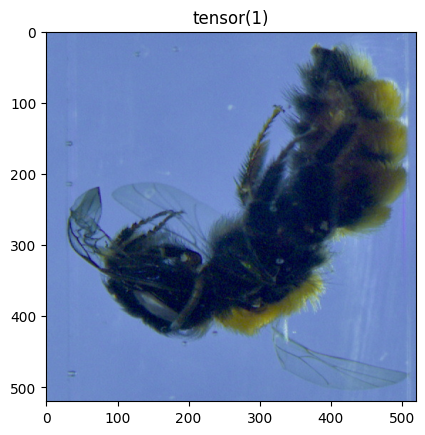

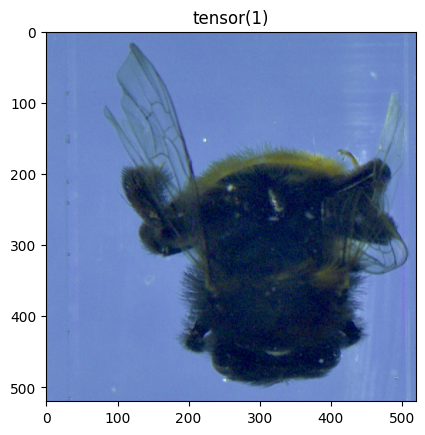

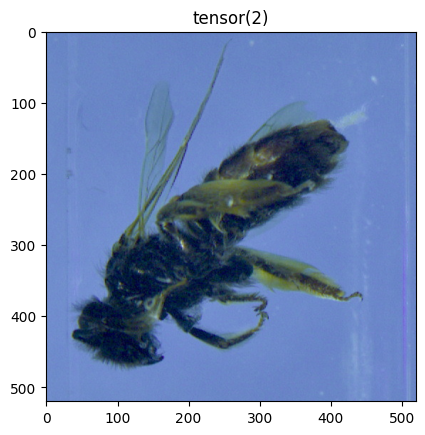

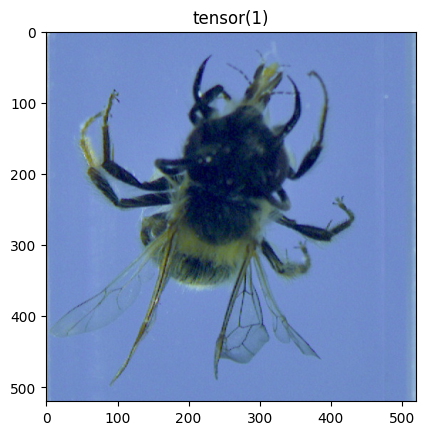

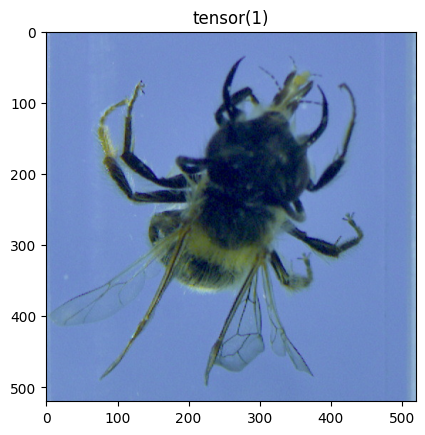

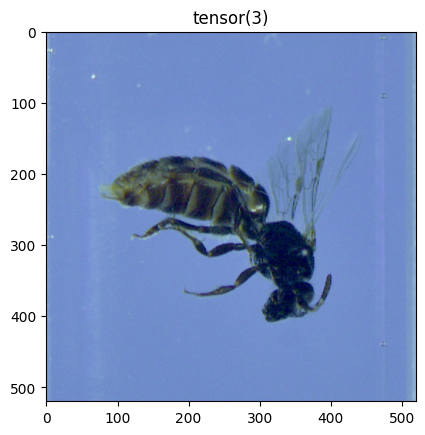

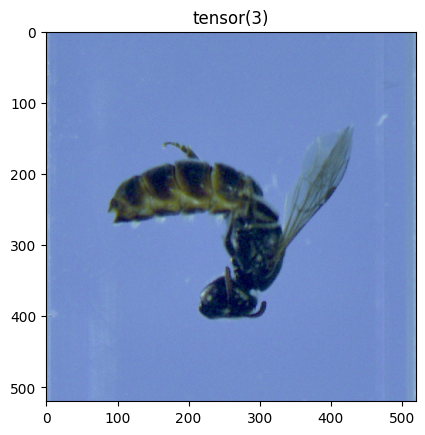

In [80]:
transform = transforms.Compose([transforms.Resize((520,520)),transforms.ToTensor()])

batch_size = 4


# Set up the dataset.
dataset = CustomImageDataset(csv_file='insects.csv', transform=transform)

# Set up the dataset.
trainloader = torch.utils.data.DataLoader(dataset,
                                          batch_size=batch_size,
                                          shuffle=True,
                                          num_workers=0)

# get some images
dataiter = iter(trainloader)
images, labels = next(dataiter)


for i in range(5): #Run through 5 batches
    images, labels = next(dataiter)
    for image, label in zip(images,labels): # Run through all samples in a batch
        plt.figure()
        plt.imshow(np.transpose(image.numpy(), (1, 2, 0)))
        plt.title(label)

<H1> Part 3: </H1>
We supply two datasets, with points drawn from a 2D feature space, and a label assigned to each data point. The data has already been assigned to train and test sets. Each file is a table, where first column is the label, and the 2nd and 3rd columns are the features. This exercise does not require a gpu.

a: describe & visualize the data


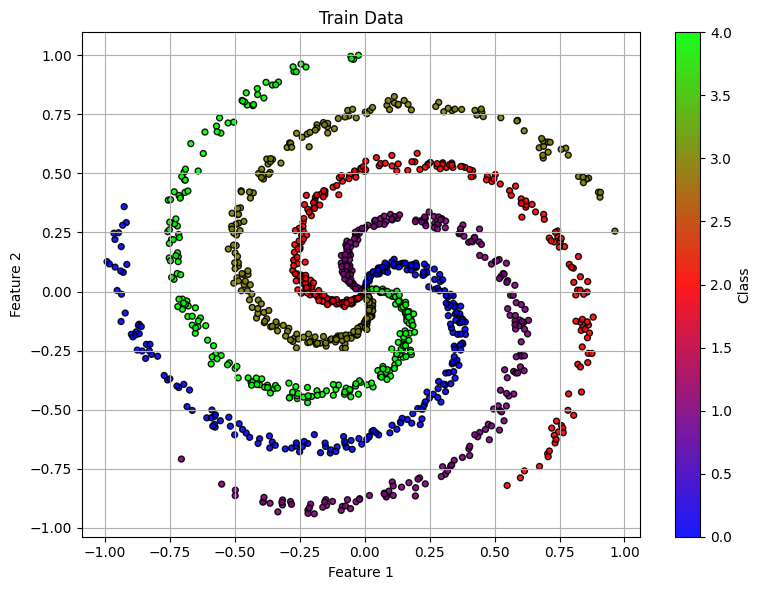

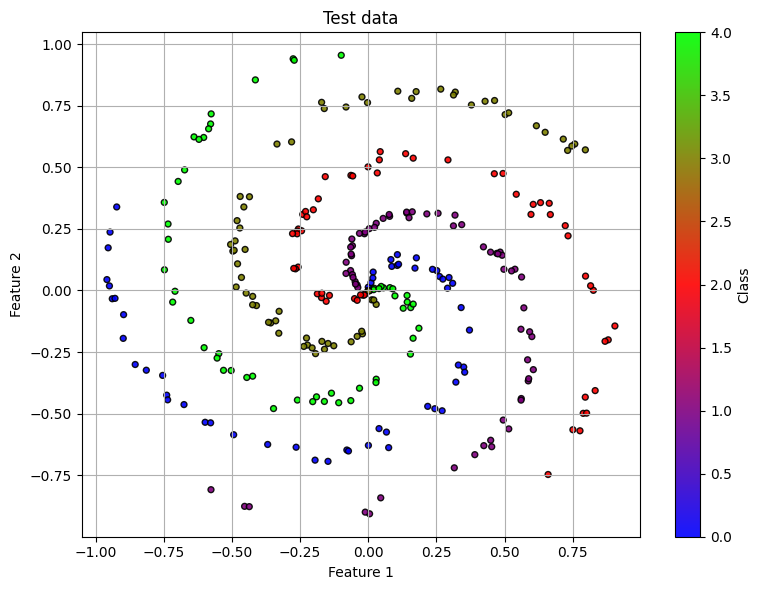

In [81]:
test_data = pd.read_csv('testData.csv', delimiter=' ')
train_data = pd.read_csv('trainData.csv', delimiter=' ')

train_labels = np.floor(np.array(train_data["label"]))
test_labels = np.floor(np.array(test_data["label"]))
# Create scatter plot
plt.figure(figsize=(8, 6))
scatter = plt.scatter(train_data["feature1"], train_data["feature2"],s=18, c=train_labels,alpha=0.9, cmap='brg', edgecolor='black')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Train Data')
plt.colorbar(scatter, label='Class')
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(test_data["feature1"], test_data["feature2"],s=18, c=test_labels,alpha=0.9, cmap='brg', edgecolor='black')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Test data')
plt.colorbar(scatter, label='Class')
plt.grid(True)
plt.tight_layout()
plt.show()



answer:

As we can see, the 5 classes form 5 spirals that all start from (0,0) and are clearly identifiable, although not linearly separable. However, this is not a concern thanks to the use of neural networks. We can also observe that the test data follows a similar distribution, which means we should be able to build a neural network capable of achieving good accuracy in classifying them.

.


b: design a neural network using pytorch to correctly assign labels


In [82]:
class CustomDataset(Dataset): # I create a custom dataset for the data
    def __init__(self, dataframe):
        self.y = dataframe.iloc[:, 0].values.astype('int64')     # First column as label
        self.X = dataframe.iloc[:, 1:].values.astype('float32')  # Other two columns as features

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        features = torch.tensor(self.X[idx], dtype=torch.float32)
        label = torch.tensor(self.y[idx], dtype=torch.long)
        return features, label


class NeuralNetwork(nn.Module): # My neural network
    def __init__(self):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(2, 8,bias=True), # I left the bias even if i am using the regularizer because I found that it still performs better
            nn.LeakyReLU(inplace=True, negative_slope=0.005), # I decided to use LeakyReLU with negative_slope very low
            nn.Linear(8, 16,bias=True),
            nn.LeakyReLU(inplace=True, negative_slope=0.005),
            nn.Linear(16, 64,bias=True),
            nn.LeakyReLU(inplace=True, negative_slope=0.005),
            nn.Linear(64, 8,bias=True),
            nn.LeakyReLU(inplace=True, negative_slope=0.005),
            nn.Linear(8, 5),
        )

    def forward(self, x):
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork().to(device)
#summary(model, input_size=(batch_size, 2), device=device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(),lr= 0.0009,weight_decay=0.00003)

In [83]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    total_loss, correct = 0, 0  # Track the total loss for the epoch

    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)
        total_loss += loss.item()  # Accumulate loss

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        # Calculate accuracy
        correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    avg_loss = total_loss / len(dataloader)  # Calculate average loss for the epoch
    avg_accuracy = correct / size

    return (avg_loss ,avg_accuracy) # Store the average loss and accuracy for the epoch

def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, accuracy = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            accuracy += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    accuracy /= size

    return (test_loss,accuracy)


epochs = 2500  #I set epochs to a very high value because I want to stop only when the validation loss is not improving anymore
best_loss = 42069.42069
epochs_non_improved = 0
for t in range(epochs):
    kf = KFold(n_splits=4, shuffle=True, random_state=2*t)
    avg_test_loss = 0
    avg_test_accuracy = 0
    avg_val_loss = 0
    avg_val_accuracy = 0
    for fold, (train_idx, val_idx) in enumerate(kf.split(train_data)):
        batch_size = 64

        train_df = train_data.iloc[train_idx].reset_index(drop=True)
        val_df = train_data.iloc[val_idx].reset_index(drop=True)

        training_dataset = CustomDataset(train_df)
        validation_dataset = CustomDataset(val_df)


        train_dataloader = DataLoader(training_dataset, batch_size=batch_size)
        test_loss ,test_accuracy = train(train_dataloader, model, loss_fn, optimizer)

        validation_dataloader = DataLoader(validation_dataset, batch_size=300)
        val_loss ,val_accuracy =  test(validation_dataloader, model, loss_fn)

        avg_test_loss += test_loss
        avg_test_accuracy += test_accuracy
        avg_val_loss += val_loss
        avg_val_accuracy += val_accuracy
    avg_test_loss /= 4
    avg_test_accuracy /= 4
    avg_val_loss /= 4
    avg_val_accuracy /= 4
    if epochs_non_improved == 50:
        print(f"Epoch {t+1}\n-----------------------------------------------")
        print(f"Train Loss: {avg_test_loss:>7f}\tTrain Accuracy: {(100*avg_test_accuracy):>0.1f}%")
        print(f"Validation Loss: {avg_val_loss:>7f}\tValidation Accuracy: {(100*avg_val_accuracy):>0.1f}%")
        print(f"------------------------------------------------------------")
        break
    elif best_loss > avg_val_loss:
        epochs_non_improved = 0
        best_loss = avg_val_loss
        torch.save(model.state_dict(), "best_model.pth")
    else:
        #print(f"NOT improved {epochs_non_improved} epochs")
        epochs_non_improved += 1
    if (t+1) % 50 == 0 or t<10:     #due to the high number of epochs i decided to print only the first 10, then each 50 and then the last one
        print(f"Epoch {t+1}\n-----------------------------------------------")
        print(f"Train Loss: {avg_test_loss:>7f}\tTrain Accuracy: {(100*avg_test_accuracy):>0.1f}%")
        print(f"Validation Loss: {avg_val_loss:>7f}\tValidation Accuracy: {(100*avg_val_accuracy):>0.1f}%")
        print(f"------------------------------------------------------------")

print("Training Done!")

best_model = NeuralNetwork().to(device)
best_model.load_state_dict(torch.load("best_model.pth"))    # I load the model that performed better on validation
testing_dataset = CustomDataset(test_data)
test_dataloader = DataLoader(testing_dataset, batch_size=299)
train_test_dataset = CustomDataset(train_data)
train_test_dataloader = DataLoader(train_test_dataset, batch_size=1200)

print("-----Result BEST model-----")
avg_loss,avg_accuracy = test(train_test_dataloader, best_model, loss_fn) #And I test it both on the training set...
print(f"Train Loss: {avg_loss:>7f}\tTrain Accuracy: {(100*avg_accuracy):>0.1f}%")
test_loss,test_accuracy = test(test_dataloader, best_model, loss_fn)    # ...and on the test set
print(f"Test Loss: {test_loss:>7f}\tTest Accuracy: {(100*test_accuracy):>0.1f}%")
print("Testing Done!")

Epoch 1
-----------------------------------------------
Train Loss: 1.606312	Train Accuracy: 24.8%
Validation Loss: 1.602146	Validation Accuracy: 26.2%
------------------------------------------------------------
Epoch 2
-----------------------------------------------
Train Loss: 1.572534	Train Accuracy: 27.6%
Validation Loss: 1.565581	Validation Accuracy: 26.3%
------------------------------------------------------------
Epoch 3
-----------------------------------------------
Train Loss: 1.498624	Train Accuracy: 31.1%
Validation Loss: 1.487059	Validation Accuracy: 30.8%
------------------------------------------------------------
Epoch 4
-----------------------------------------------
Train Loss: 1.410921	Train Accuracy: 29.1%
Validation Loss: 1.399875	Validation Accuracy: 29.0%
------------------------------------------------------------
Epoch 5
-----------------------------------------------
Train Loss: 1.339155	Train Accuracy: 32.0%
Validation Loss: 1.320406	Validation Accuracy: 32

- Describe your network:
    - My NN is a simple MLP with the following structure:
        - 5 fully connected layers with sizes of 2x8 - 8x16 - 16x64 - 64x8 - 8x5 all with bias
        - Each layer is followed by a leakyReLu as activation function apart from the last
        - A softmax at the end to do classification using the CrossEntropy loss

- Describe your training strategy:

    ---------------------------------------------------------------------------
    |architecture |learning rate |weight_decay |batch_size|test accuracy|

    - 2x8 - 8x16 - 16x8 - 8x5         | 0.008    | 0.00003 | 64 | 98.0%|
    - 2x8 - 8x16 - 16x64 - 64x8 - 8x5 | 0.008    | 0.00003 | 32 | 99.0%|
    - 2x8 - 8x16 - 16x64 - 64x8 - 8x5 | 0.0008   | 0.003   | 32 | 97.0%|
    - 2x8 - 8x16 - 16x64 - 64x8 - 8x5 | 0.0008   | 0.00003 | 32 | 99.3%|
    - 2x8 - 8x16 - 16x64 - 64x8 - 8x5 | 0.008    | 0.00003 | 64 | 99.3%|
    - 2x8 - 8x16 - 16x64 - 64x8 - 8x5 | 0.005    | 0.00006 | 64 | 99.0%|
    - 2x8 - 8x16 - 16x64 - 64x8 - 8x5 | 0.0009   | 0.00003 | 64 | 99.3%|
    - --------------------------------------------------------------------------
    I tested with multiple variations of the hyperparameters and in the end I used the Adam optimizer with a learning rate of 0.009 found by trying multiple values and a weight_decay of 0.00003 to regularize and reduce overfitting
    I used a batch size of 64 and then I've done 4-fold cross validation to trained until the Validation loss didn't improve for 50 epochs in a row and saved the parameters of the best performing model. My training converges at a minimum on the validation after more than 430 epochs, but that could be drastically decreased by increasing slightly the learning rate, in this case I decided that the training was fast enough for this trade off.

- Describe your results and discuss the observed performance

   I achieved a train accuracy of 99.8% and a test accuracy of 99.3% therefore I would say that my model has both low bias and low variance

- Visualize network performance similar to:

Text(0, 0.5, 'Feature 2')

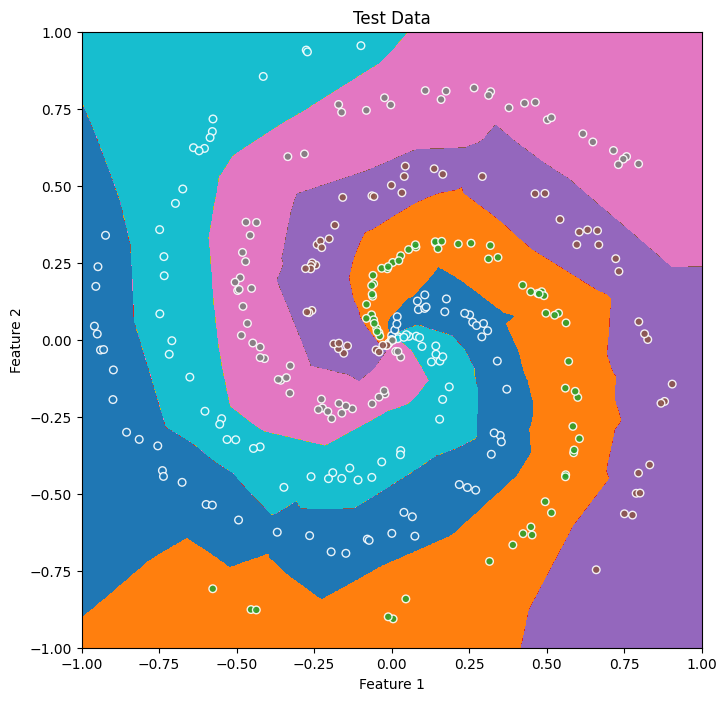

In [84]:
best_model.cpu()
dim = 1000
x,y=np.meshgrid(np.linspace(-1,1,dim),np.linspace(-1,1,dim))
xy=np.concatenate((x.reshape(-1,1),y.reshape(-1,1)),axis=1)
z=best_model(torch.tensor(xy).float()).detach().numpy()
z=np.argmax(z,1).reshape(dim,dim)
plt.figure(figsize=(8, 8))
plt.contourf(x,y,z,cmap='tab10')
plt.scatter(test_data["feature1"],test_data["feature2"],c=test_labels,cmap='tab10',alpha=0.9,s=30, edgecolor='w')
plt.title('Test Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

Text(0, 0.5, 'Feature 2')

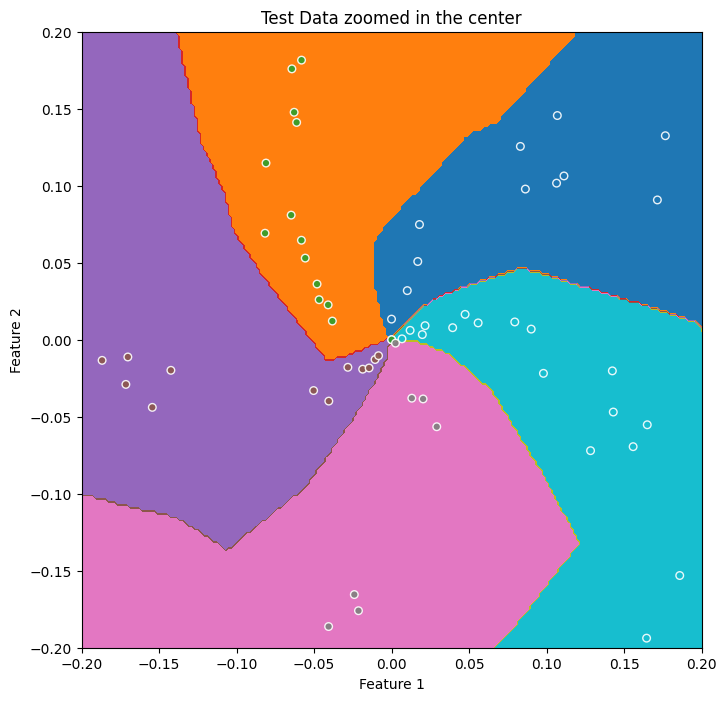

In [85]:
best_model.cpu()
dim = 1000
x,y=np.meshgrid(np.linspace(-1,1,dim),np.linspace(-1,1,dim))
xy=np.concatenate((x.reshape(-1,1),y.reshape(-1,1)),axis=1)
z=best_model(torch.tensor(xy).float()).detach().numpy()
z=np.argmax(z,1).reshape(dim,dim)
plt.figure(figsize=(8, 8))
plt.contourf(x,y,z,cmap='tab10')
plt.scatter(test_data["feature1"],test_data["feature2"],c=test_labels,cmap='tab10',alpha=0.9,s=30, edgecolor='w')
plt.xlim(-0.2,0.2)
plt.ylim(-0.2,0.2)
plt.title('Test Data zoomed in the center')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

Text(0, 0.5, 'Feature 2')

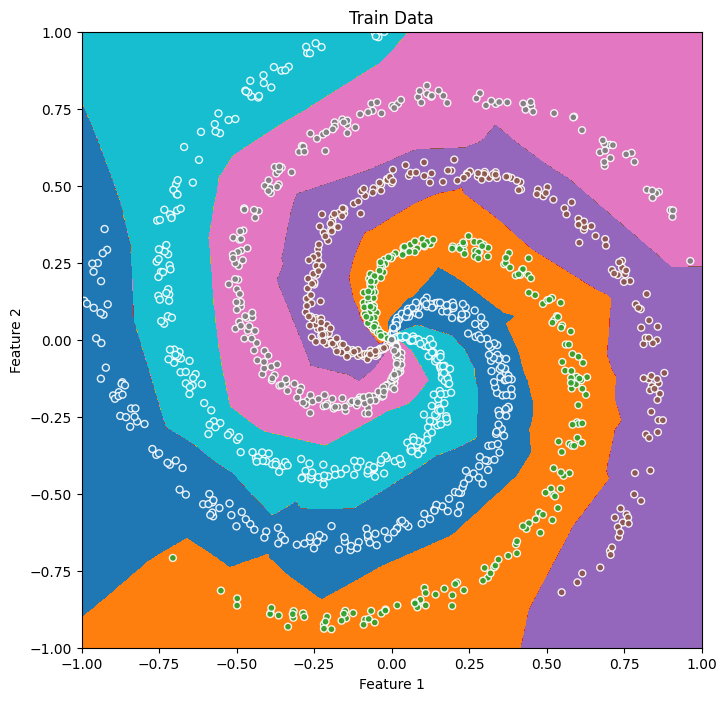

In [86]:
best_model.cpu()
x,y=np.meshgrid(np.linspace(-1,1,dim),np.linspace(-1,1,dim))
xy=np.concatenate((x.reshape(-1,1),y.reshape(-1,1)),axis=1)
z=best_model(torch.tensor(xy).float()).detach().numpy()
z=np.argmax(z,1).reshape(dim,dim)
plt.figure(figsize=(8, 8))
plt.contourf(x,y,z,cmap='tab10')
plt.scatter(train_data["feature1"],train_data["feature2"],cmap='tab10',c=train_labels,alpha=0.9,s=25, edgecolor='w')
plt.title('Train Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')